# Optical Imaging: PSF, OTF, Coherent vs. Incoherent

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch05/ch05-11-1D.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** no setup is needed for this notebook. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

## 1D PSF and OTF profiles
Uses sinc instead of jinc.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import ConnectionPatch

# ==========================================
# 0. Formatting / Style Setup
# ==========================================
plot_params = {
    'font.size': 14,
    'font.family': 'sans-serif',
    'mathtext.fontset': 'stix',
    'axes.linewidth': 1.0,
    'lines.linewidth': 2.5,
    'figure.figsize': (16, 12) # Taller figure for this layout
}
plt.rcParams.update(plot_params)

def apply_tick_style(ax):
    """Helper to apply strict tick styling."""
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.minorticks_on()
    ax.tick_params(which='both', direction="in", width=1)
    ax.tick_params(which='major', length=7)
    ax.tick_params(which='minor', length=3.5)
    ax.xaxis.set_ticks_position('both')
    ax.yaxis.set_ticks_position('both')

In [2]:
# ==========================================
# 1. Define Domain and Input Object
# ==========================================
N = 4096           # Number of points
X_max = 20.0       # Spatial extent
dx = X_max / N     # Spatial resolution

x = np.linspace(-X_max/2, X_max/2, N)

# Frequency domain setup
freqs = np.fft.fftfreq(N, d=dx)
freqs_shifted = np.fft.fftshift(freqs)

# Define Input Object O(x): Two narrow blocks (resolving power test)
def object_func(t):
    # Two 0.5-wide pulses separated by a 0.5 gap
    pulse1 = np.where((t >= -0.75) & (t <= -0.25), 1.0, 0.0)
    pulse2 = np.where((t >= 0.25) & (t <= 0.75), 1.0, 0.0)
    return pulse1 + pulse2

O_x = object_func(x)
# Spectrum of Object O(f)
O_f = np.fft.fftshift(np.fft.fft(O_x) * dx)

In [3]:
# ==========================================
# 2. Coherent System Definition
# ==========================================
# The Pupil Function P(x) is the aperture.
W = 1
Pupil_x = np.where((x >= -W/2) & (x <= W/2), 1.0, 0.0)

# Coherent OTF H_coh(f) is effectively the Pupil function.
H_coh_std = np.fft.ifftshift(Pupil_x)

# Coherent PSF h_coh(x) calculation
# 1. IFFT yields the PSF in "standard" order.
h_coh_std = np.fft.ifft(H_coh_std) / dx

# 2. Shift the PSF back to "centered" order.
# CRITICAL CHANGE: We keep this complex!
h_coh_x_complex = np.fft.fftshift(h_coh_std)

# Normalize by the complex sum (This removes any global phase offset at DC)
h_coh_x = h_coh_x_complex / np.sum(h_coh_x_complex * dx)

# For plotting OTF later
H_coh_f_shifted = Pupil_x

In [4]:
# ==========================================
# 3. Incoherent System Definition
# ==========================================
# Incoherent PSF h_inc(x) is the Intensity of the Coherent PSF.
# h_inc(x) = |h_coh(x)|^2  -> This results in a Sinc-squared shape.
h_inc_x = np.abs(h_coh_x)**2

# Normalize Incoherent PSF to unit area
h_inc_x = h_inc_x / np.sum(h_inc_x * dx)

# Incoherent OTF H_inc(f) is the FFT of the Incoherent PSF.
# FT of Sinc^2 is a Triangle function (autocorrelation of rect).
H_inc_f_complex = np.fft.fft(h_inc_x) * dx
H_inc_f_shifted = np.fft.fftshift(H_inc_f_complex)

# Normalize OTF to be 1.0 at DC (f=0)
H_inc_f_shifted = H_inc_f_shifted / np.max(np.abs(H_inc_f_shifted))

In [5]:
# ==========================================
# 4. Perform Imaging (Convolution & Multiplication)
# ==========================================

# --- Coherent Imaging ---
# Spatial Domain: Convolution in Amplitude
Img_coh_amplitude = np.convolve(O_x, h_coh_x, mode='same') * dx
# Detected image is Intensity (Amplitude squared)
Img_coh_intensity = np.abs(Img_coh_amplitude)**2

# --- Incoherent Imaging ---
# Spatial Domain: Convolution in Intensity
# Direct convolution with the intensity PSF
Img_inc_intensity = np.convolve(O_x, h_inc_x, mode='same') * dx

# Frequency Domain Verification (Multiplication)
# I_inc(f) = O(f) * H_inc(f)
I_inc_f_shifted = O_f * H_inc_f_shifted

## Coherent only

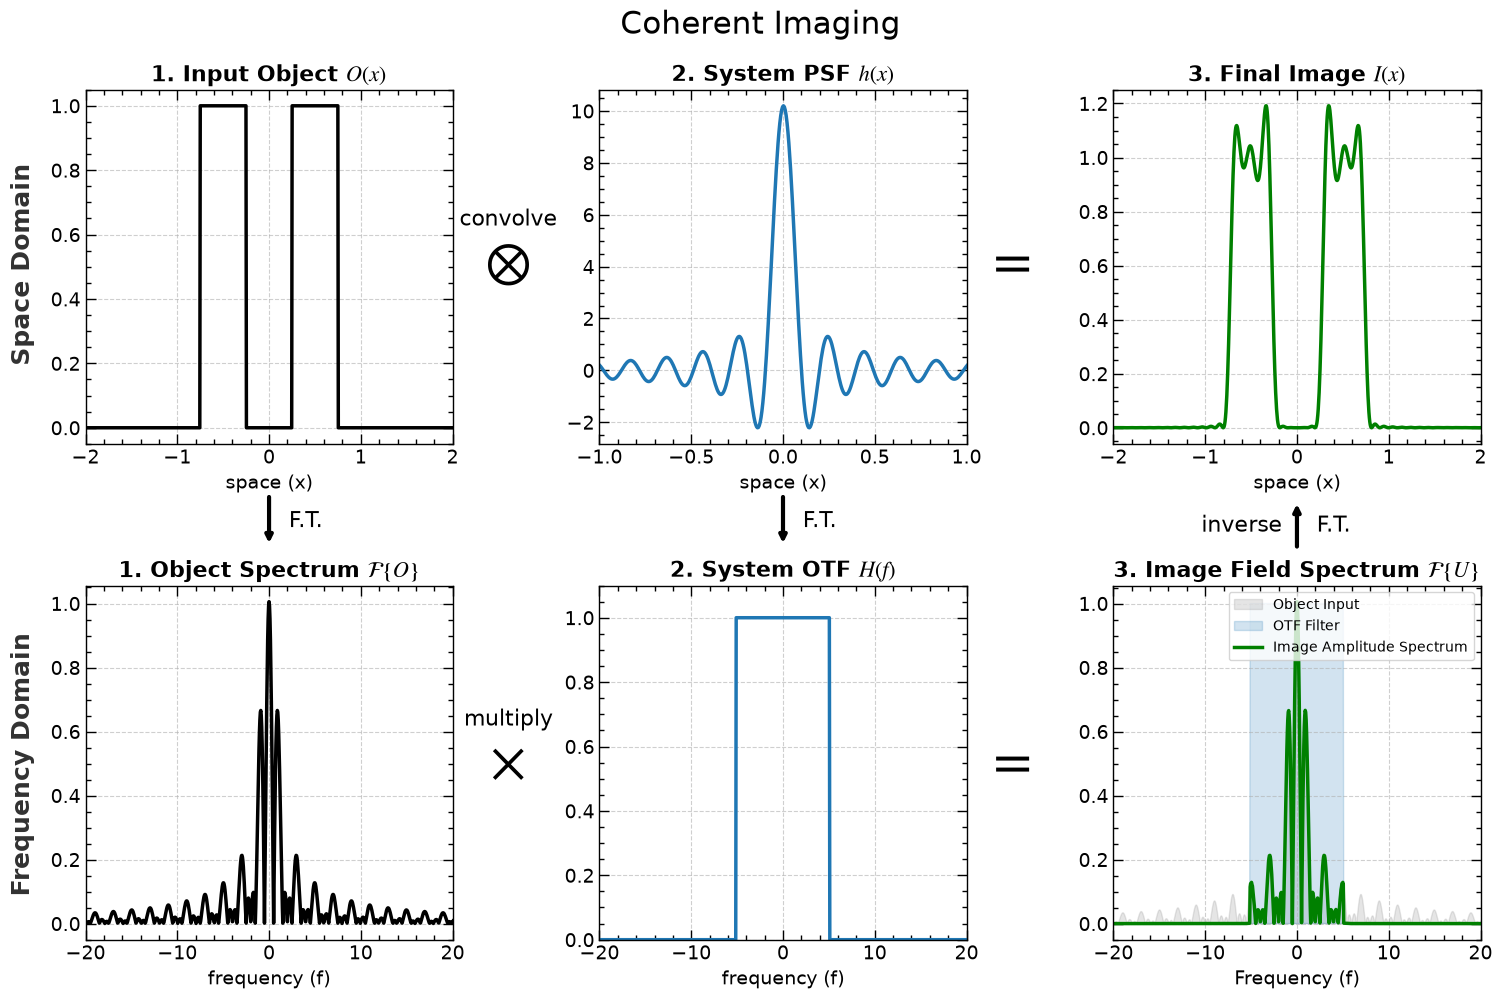

In [6]:
# ==========================================
# Plotting the Coherent Imaging Flowchart (Field Spectrum)
# ==========================================

# Settings from user
x_lim_obj = 2       
f_lim_obj = 20      

x_lim_psf = 1       
f_lim_otf = 20      

x_lim_img = 2       
f_lim_img = 20      

coh_color = '#1f77b4' # Blue
out_color = 'green'   # Green for Image Result

fig1, axes1 = plt.subplots(2, 3, figsize=(18, 10))
plt.subplots_adjust(wspace=0.4, hspace=0.4, top=0.90, bottom=0.05)

# --- ROW 1: SPATIAL DOMAIN (x) ---

# 1.1 Input Object O(x)
ax_obj_x = axes1[0, 0]
ax_obj_x.plot(x, O_x, 'k')
ax_obj_x.set_title(r"1. Input Object $O(x)$", fontsize=16, weight='bold')
ax_obj_x.set_xlabel("space (x)")
ax_obj_x.set_xlim(-x_lim_obj, x_lim_obj)
apply_tick_style(ax_obj_x)

# 1.2 System PSF h(x) (Coherent)
ax_psf = axes1[0, 1]
# Plot Real part of complex PSF
ax_psf.plot(x, np.real(h_coh_x), color=coh_color)
ax_psf.set_title(r"2. System PSF $h(x)$", fontsize=16, weight='bold')
ax_psf.set_xlabel("space (x)")
ax_psf.set_xlim(-x_lim_psf, x_lim_psf)
apply_tick_style(ax_psf)

# 1.3 Final Image I(x) (Coherent Intensity)
ax_img_x = axes1[0, 2]
ax_img_x.plot(x, Img_coh_intensity, color=out_color)
ax_img_x.set_title(r"3. Final Image $I(x)$", fontsize=16, weight='bold')
ax_img_x.set_xlabel("space (x)")
ax_img_x.set_xlim(-x_lim_img, x_lim_img)
apply_tick_style(ax_img_x)

# --- ROW 2: FREQUENCY DOMAIN (f) ---

# 2.1 Object Spectrum O(f)
ax_obj_f = axes1[1, 0]
ax_obj_f.plot(freqs_shifted, np.abs(O_f), 'k')
ax_obj_f.set_title(r"1. Object Spectrum $\mathcal{F}\{O\}$", fontsize=16, weight='bold')
ax_obj_f.set_xlabel("frequency (f)")
ax_obj_f.set_xlim(-f_lim_obj, f_lim_obj)
apply_tick_style(ax_obj_f)

# 2.2 System OTF H(f) (Coherent)
ax_otf = axes1[1, 1]
ax_otf.plot(freqs_shifted, np.abs(H_coh_f_shifted), color=coh_color)
ax_otf.set_title(r"2. System OTF $H(f)$", fontsize=16, weight='bold')
ax_otf.set_xlabel("frequency (f)")
ax_otf.set_xlim(-f_lim_otf, f_lim_otf)
ax_otf.set_ylim(0, 1.1)
apply_tick_style(ax_otf)

# 2.3 Image Spectrum (Coherent Field) -- MODIFIED
# Calculate spectrum of the FIELD (Amplitude), not Intensity
# This satisfies the linear relationship: Img_Field_Spect = Obj_Spect * OTF
Img_coh_field_f = np.fft.fftshift(np.fft.fft(Img_coh_amplitude) * dx)

ax_img_f = axes1[1, 2]

# Layer 1: Object Spectrum (Background, Gray Shaded)
ax_img_f.fill_between(freqs_shifted, 0, np.abs(O_f), color='gray', alpha=0.2, label='Object Input')

# Layer 2: OTF (Background, Blue Shaded)
ax_img_f.fill_between(freqs_shifted, 0, np.abs(H_coh_f_shifted), color=coh_color, alpha=0.2, label='OTF Filter')

# Layer 3: Image Field Spectrum (Foreground, Green Line)
ax_img_f.plot(freqs_shifted, np.abs(Img_coh_field_f), color=out_color, linewidth=2.5, label='Image Amplitude Spectrum')

ax_img_f.set_title(r"3. Image Field Spectrum $\mathcal{F}\{U\}$", fontsize=16, weight='bold')
ax_img_f.set_xlabel("Frequency (f)")
ax_img_f.set_xlim(-f_lim_img, f_lim_img)
ax_img_f.legend(fontsize=10, loc='upper right', frameon=True)
apply_tick_style(ax_img_f)

# --- Annotations ---
# Helper to draw arrows between axes
def draw_arrow(fig, ax_from, ax_to, text="", color="black"):
    xyA = (0.5, -0.15) # Bottom center of From
    xyB = (0.5, 1.1) # Top center of To
    coordsA = "axes fraction"
    coordsB = "axes fraction"
    con = ConnectionPatch(xyA=xyA, xyB=xyB, coordsA=coordsA, coordsB=coordsB,
                          axesA=ax_from, axesB=ax_to,
                          arrowstyle="-|>", shrinkB=5, linewidth=3, color=color)
    ax_from.add_artist(con)
    
    # Add text label to the arrow
    if text:
        # Calculate midpoint in display coords to place text
        # Simple hack: place text on the destination axis top
        ax_to.text(0.6, 1.15, text, transform=ax_to.transAxes, 
                   ha='center', va='bottom', fontsize=16, color=color)

# 1. Vertical Arrows (Time <-> Freq)
draw_arrow(fig1, ax_obj_x, ax_obj_f, text="F.T.")
draw_arrow(fig1, ax_psf, ax_otf, text="F.T.")
# Inverse Transform Arrow (Upwards)
con_inv = ConnectionPatch(xyA=(0.5, 1.11), xyB=(0.5, -0.15), 
                          coordsA="axes fraction", coordsB="axes fraction",
                          axesA=ax_img_f, axesB=ax_img_x,
                          arrowstyle="-|>", shrinkB=5, linewidth=3, color="black")
ax_img_f.add_artist(con_inv)
ax_img_x.text(0.35, -0.2, "inverse", transform=ax_img_x.transAxes, 
          ha='center', va='top', fontsize=16)
ax_img_x.text(0.6, -0.2, "F.T.", transform=ax_img_x.transAxes, 
          ha='center', va='top', fontsize=16)

# 2. Horizontal Operations (Mathematical Symbols)
# We place text in Figure coordinates to sit between the subplots
# Get bounding boxes to find positions
r = fig1.canvas.get_renderer()

# Row 1: Convolution
# Between Col 0 and 1
trans = fig1.transFigure
# Approximate positions based on layout
fig1.text(0.36, 0.77, "convolve", fontsize=16, ha='center', va='center') # Convolution
fig1.text(0.36, 0.725, r"$\otimes$", fontsize=40, ha='center', va='center', weight='bold') # Convolution
fig1.text(0.64, 0.725, r"$=$", fontsize=40, ha='center', va='center', weight='bold') # Equals

# Row 2: Multiplication
fig1.text(0.36, 0.27, "multiply", fontsize=16, ha='center', va='center') # Multiply
fig1.text(0.36, 0.225, r"$\times$", fontsize=40, ha='center', va='center', weight='bold') # Multiply
fig1.text(0.64, 0.225, r"$=$", fontsize=40, ha='center', va='center', weight='bold') # Equals

# Row Labels
fig1.text(0.09, 0.725, "Space Domain", rotation=90, va='center', ha='center', fontsize=18, weight='bold', color='#333')
fig1.text(0.09, 0.225, "Frequency Domain", rotation=90, va='center', ha='center', fontsize=18, weight='bold', color='#333')

plt.suptitle("Coherent Imaging", fontsize=22, y=0.98)
plt.show()

## Incoherent only

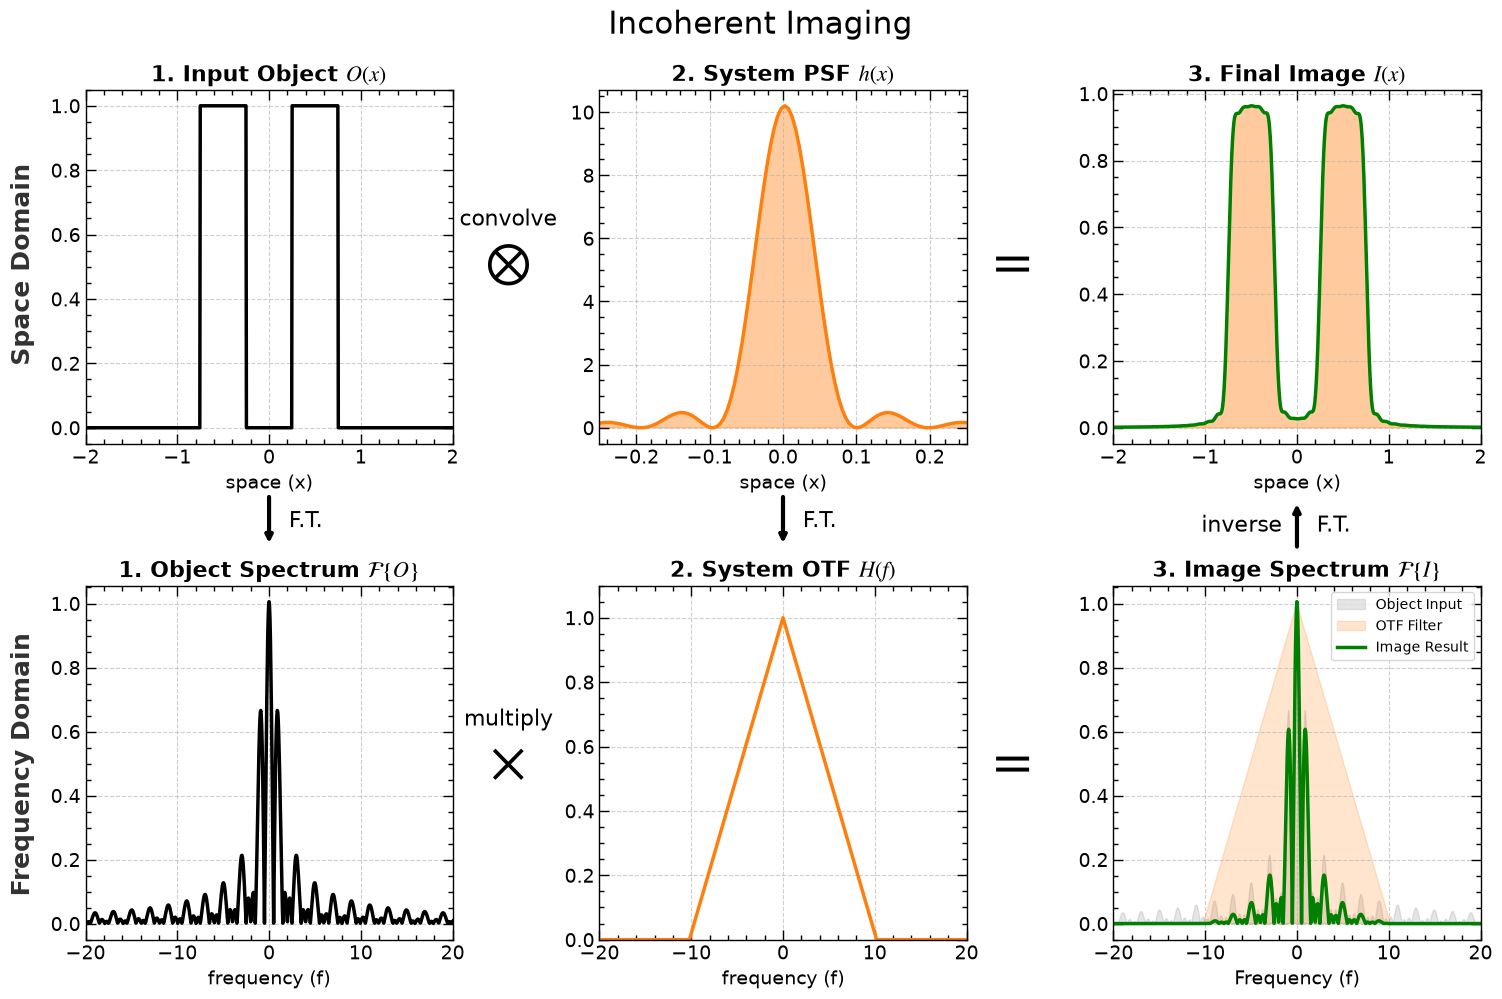

In [7]:
# ==========================================
# Plotting the Incoherent Imaging Flowchart (Robust Calculation)
# ==========================================

# Settings from user
x_lim_obj2 = 2       
f_lim_obj2 = 20      

x_lim_psf2 = 0.25    # PSF is narrow
f_lim_otf2 = 20      

x_lim_img2 = 2       
f_lim_img2 = 20      

inc_color = '#ff7f0e' # Orange
out_color2 = 'green'   # Green for Image Result

fig2, axes2 = plt.subplots(2, 3, figsize=(18, 10))
plt.subplots_adjust(wspace=0.4, hspace=0.4, top=0.90, bottom=0.05)

# --- RE-CALCULATE ROBUSTLY (Keep complex) ---
# 1. Coherent PSF (Complex)
H_coh_std2 = np.fft.ifftshift(Pupil_x)
h_coh_std2 = np.fft.ifft(H_coh_std2) / dx
h_coh_x_complex2 = np.fft.fftshift(h_coh_std2)

# 2. Incoherent PSF (Intensity = |Complex|^2)
h_inc_x2 = np.abs(h_coh_x_complex2)**2
h_inc_x2 = h_inc_x2 / np.sum(h_inc_x2 * dx) # Normalize

# 3. Incoherent OTF (FFT of PSF)
H_inc_f_complex2 = np.fft.fft(np.fft.ifftshift(h_inc_x2)) * dx
H_inc_f_shifted2 = np.fft.fftshift(H_inc_f_complex2)
H_inc_f_shifted2 = H_inc_f_shifted2 / np.max(np.abs(H_inc_f_shifted2))

# 4. Incoherent Image (Convolution)
Img_inc_intensity2 = np.convolve(O_x, h_inc_x2, mode='same') * dx

# --- ROW 1: SPATIAL DOMAIN (x) ---

# 1.1 Input Object O(x)
ax_obj_x2 = axes2[0, 0]
ax_obj_x2.plot(x, O_x, 'k')
ax_obj_x2.set_title(r"1. Input Object $O(x)$", fontsize=16, weight='bold')
ax_obj_x2.set_xlabel("space (x)")
ax_obj_x2.set_xlim(-x_lim_obj2, x_lim_obj2)
apply_tick_style(ax_obj_x2)

# 1.2 System PSF h(x) (Incoherent)
ax_psf2 = axes2[0, 1]
ax_psf2.fill_between(x, 0, h_inc_x2, color=inc_color, alpha=0.4) 
ax_psf2.plot(x, h_inc_x2, color=inc_color) 
ax_psf2.set_title(r"2. System PSF $h(x)$", fontsize=16, weight='bold')
ax_psf2.set_xlabel("space (x)")
ax_psf2.set_xlim(-x_lim_psf2, x_lim_psf2)
apply_tick_style(ax_psf2)

# 1.3 Final Image I(x) (Incoherent)
ax_img_x2 = axes2[0, 2]
ax_img_x2.fill_between(x, 0, Img_inc_intensity2, color=inc_color, alpha=0.4)
ax_img_x2.plot(x, Img_inc_intensity2, color=out_color2) # Green outline
ax_img_x2.set_title(r"3. Final Image $I(x)$", fontsize=16, weight='bold')
ax_img_x2.set_xlabel("space (x)")
ax_img_x2.set_xlim(-x_lim_img2, x_lim_img2)
apply_tick_style(ax_img_x2)

# --- ROW 2: FREQUENCY DOMAIN (f) ---

# 2.1 Object Spectrum O(f)
ax_obj_f2 = axes2[1, 0]
ax_obj_f2.plot(freqs_shifted, np.abs(O_f), 'k')
ax_obj_f2.set_title(r"1. Object Spectrum $\mathcal{F}\{O\}$", fontsize=16, weight='bold')
ax_obj_f2.set_xlabel("frequency (f)")
ax_obj_f2.set_xlim(-f_lim_obj2, f_lim_obj2)
apply_tick_style(ax_obj_f2)

# 2.2 System OTF H(f) (Incoherent)
ax_otf2 = axes2[1, 1]
ax_otf2.plot(freqs_shifted, np.abs(H_inc_f_shifted2), color=inc_color)
ax_otf2.set_title(r"2. System OTF $H(f)$", fontsize=16, weight='bold')
ax_otf2.set_xlabel("frequency (f)")
ax_otf2.set_xlim(-f_lim_otf2, f_lim_otf2)
ax_otf2.set_ylim(0, 1.1)
apply_tick_style(ax_otf2)

# 2.3 Image Spectrum I(f) (Incoherent)
# For incoherent, we stick to Intensity Spectrum, as it IS linear.
Img_inc_intensity_f = np.fft.fftshift(np.fft.fft(Img_inc_intensity2) * dx)

ax_img_f2 = axes2[1, 2]

# Layer 1: Object Spectrum (Background, Gray Shaded)
ax_img_f2.fill_between(freqs_shifted, 0, np.abs(O_f), color='gray', alpha=0.2, label='Object Input')

# Layer 2: OTF (Background, Orange Shaded)
ax_img_f2.fill_between(freqs_shifted, 0, np.abs(H_inc_f_shifted2), color=inc_color, alpha=0.2, label='OTF Filter')

# Layer 3: Image Spectrum (Foreground, Green Line)
ax_img_f2.plot(freqs_shifted, np.abs(Img_inc_intensity_f), color=out_color2, linewidth=2.5, label='Image Result')

ax_img_f2.set_title(r"3. Image Spectrum $\mathcal{F}\{I\}$", fontsize=16, weight='bold')
ax_img_f2.set_xlabel("Frequency (f)")
ax_img_f2.set_xlim(-f_lim_img2, f_lim_img2)
ax_img_f2.legend(fontsize=10, loc='upper right', frameon=True)
apply_tick_style(ax_img_f2)

# --- Annotations ---
# Helper to draw arrows between axes
def draw_arrow2(fig, ax_from, ax_to, text="", color="black"):
    xyA = (0.5, -0.15) # Bottom center of From
    xyB = (0.5, 1.1) # Top center of To
    coordsA = "axes fraction"
    coordsB = "axes fraction"
    con = ConnectionPatch(xyA=xyA, xyB=xyB, coordsA=coordsA, coordsB=coordsB,
                          axesA=ax_from, axesB=ax_to,
                          arrowstyle="-|>", shrinkB=5, linewidth=3, color=color)
    ax_from.add_artist(con)
    
    # Add text label to the arrow
    if text:
        # Calculate midpoint in display coords to place text
        # Simple hack: place text on the destination axis top
        ax_to.text(0.6, 1.15, text, transform=ax_to.transAxes, 
                   ha='center', va='bottom', fontsize=16, color=color)

# 1. Vertical Arrows (Time <-> Freq)
draw_arrow2(fig2, ax_obj_x2, ax_obj_f2, text="F.T.")
draw_arrow2(fig2, ax_psf2, ax_otf2, text="F.T.")
# Inverse Transform Arrow (Upwards)
con_inv2 = ConnectionPatch(xyA=(0.5, 1.11), xyB=(0.5, -0.15), 
                          coordsA="axes fraction", coordsB="axes fraction",
                          axesA=ax_img_f2, axesB=ax_img_x2,
                          arrowstyle="-|>", shrinkB=5, linewidth=3, color="black")
ax_img_f2.add_artist(con_inv2)
ax_img_x2.text(0.35, -0.2, "inverse", transform=ax_img_x2.transAxes, 
          ha='center', va='top', fontsize=16)
ax_img_x2.text(0.6, -0.2, "F.T.", transform=ax_img_x2.transAxes, 
          ha='center', va='top', fontsize=16)

# 2. Horizontal Operations (Mathematical Symbols)
# We place text in Figure coordinates to sit between the subplots
# Get bounding boxes to find positions
r2 = fig2.canvas.get_renderer()

# Row 1: Convolution
# Between Col 0 and 1
trans2 = fig2.transFigure
# Approximate positions based on layout
fig2.text(0.36, 0.77, "convolve", fontsize=16, ha='center', va='center') # Convolution
fig2.text(0.36, 0.725, r"$\otimes$", fontsize=40, ha='center', va='center', weight='bold') # Convolution
fig2.text(0.64, 0.725, r"$=$", fontsize=40, ha='center', va='center', weight='bold') # Equals

# Row 2: Multiplication
fig2.text(0.36, 0.27, "multiply", fontsize=16, ha='center', va='center') # Multiply
fig2.text(0.36, 0.225, r"$\times$", fontsize=40, ha='center', va='center', weight='bold') # Multiply
fig2.text(0.64, 0.225, r"$=$", fontsize=40, ha='center', va='center', weight='bold') # Equals

# Row Labels
fig2.text(0.09, 0.725, "Space Domain", rotation=90, va='center', ha='center', fontsize=18, weight='bold', color='#333')
fig2.text(0.09, 0.225, "Frequency Domain", rotation=90, va='center', ha='center', fontsize=18, weight='bold', color='#333')

plt.suptitle("Incoherent Imaging", fontsize=22, y=0.98)
plt.show()